# AQI data: from EPA county files to the state target

**What this notebook does:** reads the EPA's annual AQI-by-county files, keeps the 50 states + DC, decides which county-years count toward a state's air quality, and builds the state-level target used in `Supervised_Learning.ipynb`.

**Input:** `Datasets/AQI/AQI_zipfiles/annual_aqi_by_county_<year>.zip`, one file per year for 1980–2024, downloaded from the EPA AirData site (aqs.epa.gov/aqsweb/airdata/download_files.html).

**Outputs** (both in `Datasets/AQI/`):
| File | Contents | Used by |
|---|---|---|
| `AQI_merged.csv` | every county-year in the 50 states + DC, all EPA columns, plus `Percent Moderate Days` | `County_Level_Analysis.ipynb`, `EDA_AQIMerged.ipynb` |
| `AQI_state_target.csv` | one row per state-year: Median AQI from qualifying counties, number of qualifying counties, main-pollutant day counts. `State` is the two-letter postal code, to match SEDS | `Supervised_Learning.ipynb` |

**How to read this notebook:** each section explains the decision it makes. Any claim about the data is followed by the code cell that checks it.

| Section | Content |
|---|---|
| 1 | Setup |
| 2 | Read and combine the yearly county files |
| 3 | Which county-years count toward a state's AQI, and why |
| 4 | Build and save the state target |

## 1. Setup

In [3]:
import sys
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

# ---- Settings ----
ID_COLS = ["State", "Year"]
TARGET_COL = "Median AQI"
FIRST_YEAR, LAST_YEAR = 1980, 2024
TEST_START = 2020                          # first test year in Supervised_Learning.ipynb (only used to report test-year counts)

# Which county-years count toward a state's Median AQI (justified in section 3)
MIN_DAYS = 180                             # county-year needs >= 180 days with an AQI value
REQUIRE_O3_PM25 = True                     # ...and ozone or PM2.5 as the main pollutant on >= 1 day

NON_US_AREAS = ["Canada", "Country Of Mexico", "Guam", "Puerto Rico", "Virgin Islands"]   # in the EPA files, but no SEDS energy data
POLLUTANT_DAYS = ["Days CO", "Days NO2", "Days Ozone", "Days PM2.5", "Days PM10"]

# EPA files use full state names; SEDS uses two-letter postal codes. The state target is saved with codes (section 4).
STATE_CODES = {"Alabama": "AL", "Alaska": "AK", "Arizona": "AZ", "Arkansas": "AR", "California": "CA", "Colorado": "CO",
               "Connecticut": "CT", "Delaware": "DE", "District Of Columbia": "DC", "Florida": "FL", "Georgia": "GA",
               "Hawaii": "HI", "Idaho": "ID", "Illinois": "IL", "Indiana": "IN", "Iowa": "IA", "Kansas": "KS",
               "Kentucky": "KY", "Louisiana": "LA", "Maine": "ME", "Maryland": "MD", "Massachusetts": "MA",
               "Michigan": "MI", "Minnesota": "MN", "Mississippi": "MS", "Missouri": "MO", "Montana": "MT",
               "Nebraska": "NE", "Nevada": "NV", "New Hampshire": "NH", "New Jersey": "NJ", "New Mexico": "NM",
               "New York": "NY", "North Carolina": "NC", "North Dakota": "ND", "Ohio": "OH", "Oklahoma": "OK",
               "Oregon": "OR", "Pennsylvania": "PA", "Rhode Island": "RI", "South Carolina": "SC", "South Dakota": "SD",
               "Tennessee": "TN", "Texas": "TX", "Utah": "UT", "Vermont": "VT", "Virginia": "VA", "Washington": "WA",
               "West Virginia": "WV", "Wisconsin": "WI", "Wyoming": "WY"}

# Chart colors (validated categorical palette: slot 1 blue) and quiet axes
BLUE, GRAY, INK, INK2 = "#2a78d6", "#a3a29b", "#0b0b0b", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GRAY,
                     "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "axes.titlecolor": INK,
                     "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "figure.dpi": 110})

# Data location: the repo's Datasets/AQI folder, found from the repo root or from Notebooks/.
# In Colab, point AQI_DIR at the same folder on your Drive (adjust the path if yours differs).
if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/gdrive")
    AQI_DIR = Path("/content/gdrive/MyDrive/SIADS_696_Milestone_II/Datasets/AQI")
else:
    REPO_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Datasets").is_dir()), Path.cwd())
    AQI_DIR = REPO_ROOT / "Datasets" / "AQI"
ZIP_DIR = AQI_DIR / "AQI_zipfiles"
print("AQI folder:", AQI_DIR)

AQI folder: /Users/hayleytice/SIADS_696_F26_Team10/Datasets/AQI


## 2. Read and combine the yearly county files
Each zip holds one CSV for one year. Every file should have the same columns, and each county should appear at most once per year. Both are checked before combining.

In [5]:
zip_paths = sorted(ZIP_DIR.glob("annual_aqi_by_county_*.zip"))
yearly = []
for path in zip_paths:
    with zipfile.ZipFile(path) as zf:
        (name,) = zf.namelist()                       # exactly one CSV per zip
        yearly.append(pd.read_csv(zf.open(name)))

columns = {tuple(d.columns) for d in yearly}
assert len(columns) == 1, f"files have different columns: {columns}"
raw = pd.concat(yearly, ignore_index=True)
assert sorted(raw.Year.unique()) == list(range(FIRST_YEAR, LAST_YEAR + 1)), "expected one file per year"
assert not raw.duplicated(["State", "County", "Year"]).any(), "a county appears twice in one year"

print(f"{len(zip_paths)} files, {len(raw)} county-years, years {raw.Year.min()}-{raw.Year.max()}, {raw.State.nunique()} 'states'")
print("columns:", list(raw.columns))

45 files, 41549 county-years, years 1980-2024, 56 'states'
columns: ['State', 'County', 'Year', 'Days with AQI', 'Good Days', 'Moderate Days', 'Unhealthy for Sensitive Groups Days', 'Unhealthy Days', 'Very Unhealthy Days', 'Hazardous Days', 'Max AQI', '90th Percentile AQI', 'Median AQI', 'Days CO', 'Days NO2', 'Days Ozone', 'Days PM2.5', 'Days PM10']


### 2.1 Keep the 50 states + DC
The EPA files also cover Canada, Mexico and three US territories. None of them have SEDS energy data, so they can't be used in the models.

In [7]:
print("county-years per non-US area (dropped):", raw[raw.State.isin(NON_US_AREAS)].State.value_counts().to_dict())
county_all = raw[~raw.State.isin(NON_US_AREAS)].reset_index(drop=True)
assert county_all.State.nunique() == 51
assert set(county_all.State) == set(STATE_CODES), "every state name needs a two-letter code"
print(f"kept: {len(county_all)} county-years in {county_all.State.nunique()} states (50 + DC)")

county-years per non-US area (dropped): {'Puerto Rico': 443, 'Country Of Mexico': 80, 'Virgin Islands': 80, 'Canada': 19, 'Guam': 3}
kept: 40924 county-years in 51 states (50 + DC)


### 2.2 Save `AQI_merged.csv`
All EPA columns are kept, plus `Percent Moderate Days` (moderate days ÷ days with AQI), which `EDA_AQIMerged.ipynb` uses. The file keeps a leading index column, so notebooks that read it with `index_col=0` keep working.

In [9]:
merged_out = county_all.assign(**{"Percent Moderate Days": county_all["Moderate Days"] / county_all["Days with AQI"]})
merged_out.to_csv(AQI_DIR / "AQI_merged.csv")
print(f"saved {AQI_DIR / 'AQI_merged.csv'}: {merged_out.shape[0]} rows x {merged_out.shape[1]} columns")

saved /Users/hayleytice/SIADS_696_F26_Team10/Datasets/AQI/AQI_merged.csv: 40924 rows x 19 columns


## 3. Which county-years count toward a state's AQI
The state target is each state's annual Median AQI: the average of its counties' Median AQI, weighted by each county's days with AQI. The county file has a row for every county with at least one monitor that year, so not every county-year measures the same thing. Two kinds of county-years would distort a state average, and each is checked below:
* **Short coverage (< 180 days):** mostly particulate (PM10 or PM2.5) monitors that only report on some days, so the county's AQI rests on one intermittently sampled pollutant (3.1).
* **No ozone or PM2.5 monitoring:** `Days Ozone` / `Days PM2.5` count the days each pollutant was the *main* one. If neither ever is, the county most likely only monitors CO, NO2 or PM10, which read much lower. Its AQI then reflects missing monitors, not cleaner air (3.2).

**Why filter:** if those county-years shifted the state average, a model would partly learn *which monitors existed*, not air quality. This matters most because the share of such county-years changes over time (3.4). So only qualifying county-years (≥ 180 days, ozone or PM2.5 the main pollutant on at least one day) count toward the state value. State-years with no qualifying county are dropped.

In [11]:
def days_weighted_state_aqi(county_rows):
    # State Median AQI = county Median AQI weighted by days with AQI
    g = county_rows.assign(w_aqi=county_rows[TARGET_COL] * county_rows["Days with AQI"]).groupby(ID_COLS)[["w_aqi", "Days with AQI"]].sum()
    return (g.w_aqi / g["Days with AQI"]).rename(TARGET_COL).reset_index()

county = county_all.copy()
county["County_ID"] = county["State"] + "|" + county["County"]          # county names like "Washington" repeat across states
county["dev_from_state_median"] = county[TARGET_COL] - county.groupby(ID_COLS)[TARGET_COL].transform("median")
county["main_pollutant"] = county[POLLUTANT_DAYS].idxmax(axis=1).str.replace("Days ", "")
county["coverage"] = np.where(county["Days with AQI"] >= MIN_DAYS, f">= {MIN_DAYS} days", f"< {MIN_DAYS} days")
county["o3_or_pm25_main"] = (county["Days Ozone"] + county["Days PM2.5"]) > 0
print(f"{county.County_ID.nunique()} counties, {len(county)} county-years in the 50 states + DC")

1508 counties, 40924 county-years in the 50 states + DC


### 3.1 Coverage: why ≥ 180 days
How far each county's Median AQI sits from its state's median that year, grouped by the number of days with an AQI value, along with each group's most common main pollutant. If short-coverage county-years are unrepresentative, they should sit further from their state.

,county_years,median_abs_dev,main: CO,main: NO2,main: Ozone,main: PM10,main: PM2.5
days_bin,,,,,,,
"(0, 60]",3055,12.0,0.00,0.00,0.03,0.84,0.12
"(60, 120]",3205,8.0,0.01,0.01,0.07,0.25,0.67
"(120, 180]",1789,5.5,0.02,0.01,0.48,0.16,0.34
"(180, 240]",4489,3.0,0.01,0.01,0.94,0.02,0.02
"(240, 300]",3618,3.0,0.02,0.01,0.89,0.03,0.04
"(300, 366]",24768,5.0,0.04,0.06,0.52,0.04,0.34


most common day counts among county-years with <= 70 days: {61: 396, 60: 386, 59: 319, 58: 266}


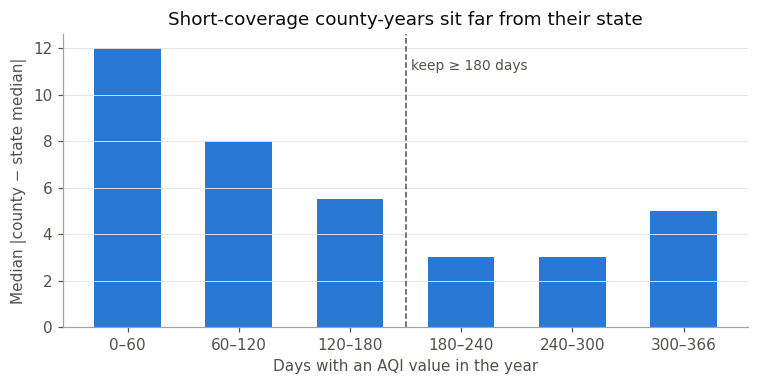

In [13]:
county["days_bin"] = pd.cut(county["Days with AQI"], [0, 60, 120, 180, 240, 300, 366])
days_table = county.groupby("days_bin", observed=True).agg(county_years=(TARGET_COL, "size"),
                                                           median_abs_dev=("dev_from_state_median", lambda x: x.abs().median()))
days_table = days_table.join(pd.crosstab(county.days_bin, county.main_pollutant, normalize="index").add_prefix("main: "))
display(days_table.round(2))
print("most common day counts among county-years with <= 70 days:",
      county.loc[county["Days with AQI"] <= 70, "Days with AQI"].value_counts().head(4).to_dict())

fig, ax = plt.subplots(figsize=(7, 3.6))
labels = [f"{int(b.left)}–{int(b.right)}" for b in days_table.index]
ax.bar(labels, days_table.median_abs_dev, color=BLUE, width=0.6)
ax.axvline(2.5, color=INK2, lw=1, ls="--")
ax.text(2.55, days_table.median_abs_dev.max() * 0.92, f"keep ≥ {MIN_DAYS} days", color=INK2, fontsize=9)
ax.set(xlabel="Days with an AQI value in the year", ylabel="Median |county − state median|",
       title="Short-coverage county-years sit far from their state")
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

**Reading this:**
* The deviation from the state median drops sharply up to 180 days and stays lower from there on, so **≥ 180 days** is the cut-off. More coverage beyond that doesn't keep reducing the deviation: the full-year bin sits slightly above the 180–300 bins.
* The short-coverage bins are mostly particulate monitors. PM10 dominates the 0–60 bin, with a spike at 60–61 days, and PM2.5 dominates the 60–120 bin. This pattern fits particulate monitors that sample only every sixth or third day (an EPA sampling practice; outside knowledge, not shown by this data). A county-year like that reflects one intermittently sampled pollutant, not the county's overall air quality.
* Seasonal ozone monitors mostly fall in the 180–240 bin (mainly ozone) and are **kept**. That bin is tied for the smallest deviation (with 240–300 days).

### 3.2 Pollutants: why ozone or PM2.5 must be the main pollutant at least once
A county's AQI on a given day is the highest of the pollutants it *monitors*, so it depends on which monitors exist. Among county-years that already pass the 180-day rule, compare those where ozone or PM2.5 is ever the main pollutant with those where it never is.

In [16]:
full = county[county["Days with AQI"] >= MIN_DAYS]
display(full.groupby("o3_or_pm25_main").agg(county_years=(TARGET_COL, "size"), median_aqi=(TARGET_COL, "median"),
                                            median_dev_from_state=("dev_from_state_median", "median")).round(2))
no_o3 = full[~full.o3_or_pm25_main]
print("main-pollutant days in county-years with no ozone/PM2.5 main days:",
      (no_o3[POLLUTANT_DAYS].sum() / no_o3[POLLUTANT_DAYS].sum().sum()).round(2).to_dict())

# Example: two Wyoming counties whose main pollutant switched after 2019
wy = county[county.County_ID.isin(["Wyoming|Uinta", "Wyoming|Carbon"]) & county.Year.between(2017, 2024)]
wy.pivot(index="Year", columns="County_ID", values=TARGET_COL).join(
    wy.pivot(index="Year", columns="County_ID", values="main_pollutant"), rsuffix=" main pollutant")

,county_years,median_aqi,median_dev_from_state
o3_or_pm25_main,,,
False,1486,21.0,-10.0
True,31466,42.0,0.5


main-pollutant days in county-years with no ozone/PM2.5 main days: {'Days CO': 0.31, 'Days NO2': 0.22, 'Days Ozone': 0.0, 'Days PM2.5': 0.0, 'Days PM10': 0.47}


County_ID,Wyoming|Carbon,Wyoming|Uinta,Wyoming|Carbon main pollutant,Wyoming|Uinta main pollutant
Year,,,,
2017,43,44,Ozone,Ozone
2018,42,44,Ozone,Ozone
2019,43,44,Ozone,Ozone
2020,8,40,NO2,Ozone
2021,10,7,NO2,PM10
2022,9,7,NO2,PM10
2023,8,6,NO2,PM10
2024,8,7,NO2,PM10


**Reading this:** county-years where ozone or PM2.5 is never the main pollutant read about half the AQI of the others and sit far below their state's median. Their main-pollutant days are all CO, NO2 or PM10. The Wyoming example shows what happens when a county stops reporting ozone: its AQI falls from the 40s to single digits from one year to the next. Air quality didn't change that much; the pollutant being reported did. Keeping such county-years would make the state target partly a record of which monitors existed.

### 3.3 Both rules together

In [19]:
county.groupby(["coverage", "o3_or_pm25_main"]).agg(county_years=(TARGET_COL, "size"), median_aqi=(TARGET_COL, "median"),
                                                    median_abs_dev_from_state=("dev_from_state_median", lambda x: x.abs().median())).round(2)

county_years  median_aqi  median_abs_dev_from_state
coverage    o3_or_pm25_main                                                     
< 180 days  False                    3672        20.0                      13.00
            True                     4300        40.0                       7.00
>= 180 days False                    1486        21.0                      12.75
            True                    31466        42.0                       4.00

Only the `>= 180 days` + ozone/PM2.5 group sits close to its state's median. The other groups deviate several AQI points, and the no-ozone/PM2.5 groups read well below the state.

### 3.4 Why it matters for modeling: the excluded county-years change over time
If the excluded county-years were a steady share every year, including them would add noise. If their share changes over time, including them would add a **trend** that comes from the monitoring network, which a model with Year and energy features could mistake for a real effect. For comparison, the second table computes the state value both ways, with every county-year and with only qualifying ones. The all-county version is shown only for this check and isn't saved.

In [22]:
county["excluded"] = ~((county["Days with AQI"] >= MIN_DAYS) & county.o3_or_pm25_main)
period_labels = ["1980s", "1990s", "2000s", "2010s", "2020-24"]
period = pd.cut(county.Year, [1979, 1989, 1999, 2009, 2019, 2024], labels=period_labels)
display(county.groupby(period, observed=True).agg(county_years=("excluded", "size"), share_excluded=("excluded", "mean"),
                                                  share_under_180_days=("coverage", lambda s: (s != f">= {MIN_DAYS} days").mean())).round(3))

all_counties = days_weighted_state_aqi(county)
qual_only = days_weighted_state_aqi(county[~county.excluded])
shift = qual_only.merge(all_counties, on=ID_COLS, suffixes=("_qualifying", "_all"))
shift["difference"] = shift[f"{TARGET_COL}_qualifying"] - shift[f"{TARGET_COL}_all"]
shift_period = pd.cut(shift.Year, [1979, 1989, 1999, 2009, 2019, 2024], labels=period_labels)
print("state value from qualifying counties minus value from all counties:")
shift.groupby(shift_period, observed=True).difference.agg(
    state_years="size", mean_difference="mean", share_differing_by_more_than_3=lambda d: (d.abs() > 3).mean()).round(3)

,county_years,share_excluded,share_under_180_days
Year,,,
1980s,5523,0.301,0.219
1990s,9347,0.374,0.306
2000s,10835,0.244,0.228
2010s,10276,0.122,0.108
2020-24,4943,0.081,0.068


state value from qualifying counties minus value from all counties:


,state_years,mean_difference,share_differing_by_more_than_3
Year,,,
1980s,478,1.821,0.264
1990s,501,2.883,0.381
2000s,510,1.182,0.169
2010s,510,0.989,0.122
2020-24,255,0.794,0.094


**Reading this:** about a third of county-years before 2000 fail the rules, against under a tenth in 2020–24. Because the excluded county-years read low, including them pulls the state value down most in the early years. That would make AQI appear to fall less over time than the qualifying monitors show, and the share of state-years affected by more than 3 AQI points shrinks from the 1990s to the 2020s. The filter removes this monitoring-network trend from the target.

## 4. Build and save the state target
Apply both rules, then compute each state-year's days-weighted Median AQI from the qualifying county-years. `State` is saved as the two-letter postal code (`AK`, `AL`, …) so the file joins directly with the SEDS energy data. Two more columns are saved for later analysis in `Supervised_Learning.ipynb`:
* `n_counties`: number of qualifying counties (the failure analysis flags state-years with few counties as thinly monitored);
* `Days CO` … `Days PM10`: main-pollutant day counts summed over qualifying counties (used to check the Hawaii failure case).

In [25]:
keep = county["Days with AQI"] >= MIN_DAYS
if REQUIRE_O3_PM25:
    keep &= county["o3_or_pm25_main"]
qualifying = county[keep]

state_target = (days_weighted_state_aqi(qualifying)
                .merge(qualifying.groupby(ID_COLS).County.nunique().rename("n_counties").reset_index(), on=ID_COLS)
                .merge(qualifying.groupby(ID_COLS)[POLLUTANT_DAYS].sum().reset_index(), on=ID_COLS)
                .sort_values(ID_COLS).reset_index(drop=True))

gaps = pd.DataFrame(sorted(set(zip(county.State, county.Year)) - set(zip(state_target.State, state_target.Year))), columns=ID_COLS)
print(f"county-years kept: {keep.sum()} of {len(county)} ({keep.mean():.0%})")
print(f"state-years with county data but no qualifying county (dropped): {len(gaps)}, years {gaps.Year.min()}-{gaps.Year.max()}, "
      f"in test years: {int((gaps.Year >= TEST_START).sum())}")
print("  by state:", gaps.groupby("State").Year.agg(lambda y: f"{y.min()}-{y.max()}").to_dict())
print(f"state-years in the target: {len(state_target)} ({state_target.Year.min()}-{state_target.Year.max()}, {state_target.State.nunique()} states)")

step = county[county["Days with AQI"] >= MIN_DAYS]
steps = [("all county-years (50 states + DC)", county), (f"days >= {MIN_DAYS}", step),
         ("+ ozone or PM2.5 main pollutant on >= 1 day", step[step.o3_or_pm25_main])]
pd.DataFrame([{"step": s, "counties": d.County_ID.nunique(), "county_years": len(d),
               "test_county_years": int((d.Year >= TEST_START).sum()), "states": d.State.nunique()} for s, d in steps]).set_index("step")

county-years kept: 31466 of 40924 (77%)
state-years with county data but no qualifying county (dropped): 32, years 1980-1998, in test years: 0
  by state: {'Alaska': '1982-1987', 'Idaho': '1980-1992', 'Montana': '1984-1987', 'South Dakota': '1985-1998', 'Wyoming': '1984-1986'}
state-years in the target: 2254 (1980-2024, 51 states)


,counties,county_years,test_county_years,states
step,,,,
all county-years (50 states + DC),1508,40924,4943,51
days >= 180,1250,32952,4608,51
+ ozone or PM2.5 main pollutant on >= 1 day,1201,31466,4543,51


In [26]:
state_target["State"] = state_target["State"].map(STATE_CODES)          # full name -> SEDS postal code
assert state_target.State.notna().all() and state_target.State.nunique() == 51
state_target.to_csv(AQI_DIR / "AQI_state_target.csv", index=False)
print(f"saved {AQI_DIR / 'AQI_state_target.csv'}: {state_target.shape[0]} rows, columns {list(state_target.columns)}")
state_target.describe().round(2)

saved /Users/hayleytice/SIADS_696_F26_Team10/Datasets/AQI/AQI_state_target.csv: 2254 rows, columns ['State', 'Year', 'Median AQI', 'n_counties', 'Days CO', 'Days NO2', 'Days Ozone', 'Days PM2.5', 'Days PM10']


,Year,Median AQI,n_counties,Days CO,Days NO2,Days Ozone,Days PM2.5,Days PM10
count,2254.00,2254.00,2254.00,2254.00,2254.00,2254.00,2254.00,2254.0
mean,2002.29,41.84,13.96,157.01,264.77,2675.52,1339.52,143.3
std,12.92,6.70,10.99,266.29,515.02,2285.77,1946.15,238.1
min,1980.00,18.00,1.00,0.00,0.00,19.00,0.00,0.0
25%,1991.00,37.80,5.00,0.00,10.00,895.50,0.00,2.0
50%,2002.00,41.88,11.00,18.00,76.00,1981.50,462.00,42.0
75%,2013.00,45.68,20.00,207.00,274.75,4001.00,1960.50,187.0
max,2024.00,73.92,53.00,2177.00,3824.00,13607.00,9722.00,1829.0
